In [65]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

In [66]:
plt.rcParams['font.family'] = 'Times New Roman'
plt.rcParams['font.size'] = 16
plt.rcParams['mathtext.fontset'] = 'custom'
plt.rcParams['mathtext.rm'] = 'Times New Roman'
plt.rcParams['mathtext.it'] = 'Times New Roman:italic'
plt.rcParams['mathtext.bf'] = 'Times New Roman:bold'

pd.set_option('display.max_colwidth', None)  # Снять ограничение на ширину колонок
pd.set_option('display.width', None)  # Снять ограничение на ширину вывода
pd.set_option('display.max_columns', None)  # Показать все колонки


In [67]:
p_nom = 20e6
bar_e_0 = 0.36
#name = 'С-5' # 0.057
#name = 'С-8' # 0.08
#name = 'С-13' # 0.122
#name = '9М27Ф' # 0.22
#name = 'С-24' # 0.24
#name = '9М55' # 0.3
name = 'Х-15' # 0.455

In [68]:


# ============================================================
# 1. ЗАГРУЗКА ДАННЫХ
# ============================================================
FILE = f"MC_results_{name}_{bar_e_0}_{p_nom/1e6:.0f}.xlsx"
df = pd.read_excel(FILE, sheet_name="Sheet1")


PARAMS = {
    "I_ud":  "I_sp", 
    "I_p":   "I_p",
    "t_p": "t_end",
}


ОТЧЁТ ПО СХОДИМОСТИ МЕТОДА МОНТЕ-КАРЛО (окно = 350 итераций, интервал = 3σ)


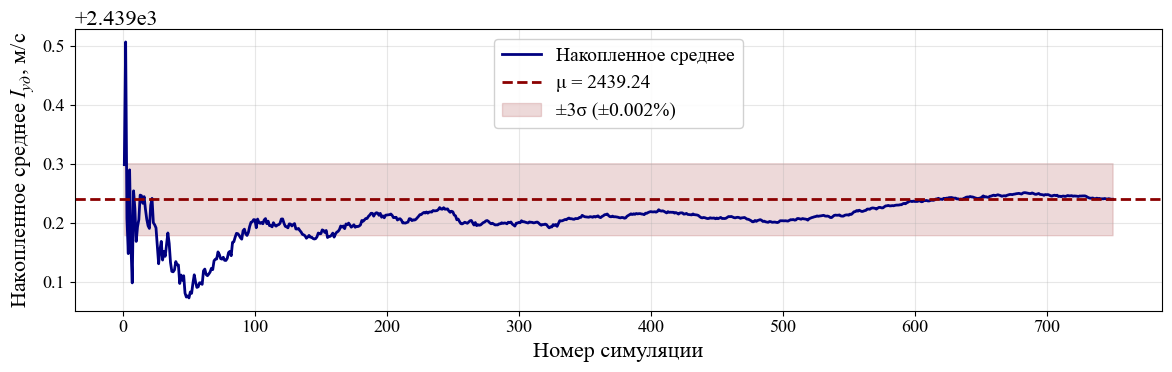

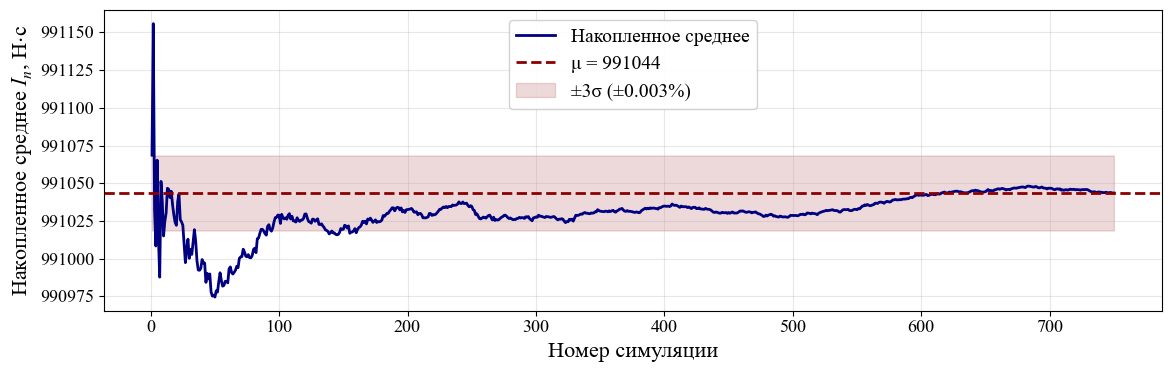

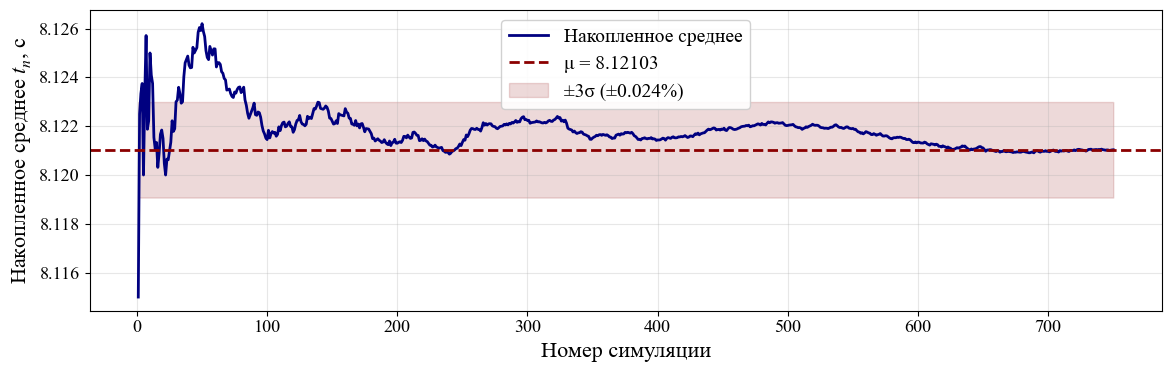


АНАЛИЗ ЗАВЕРШЁН


In [69]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# ОЦЕНКА СХОДИМОСТИ МЕТОДА МОНТЕ-КАРЛО
# по последним 100 итерациям (окно = 100)
# ============================================================

plt.rcParams['font.family'] = 'Times New Roman'
plt.rcParams['font.size'] = 16
plt.rcParams['mathtext.fontset'] = 'custom'
plt.rcParams['mathtext.rm'] = 'Times New Roman'
plt.rcParams['mathtext.it'] = 'Times New Roman:italic'
plt.rcParams['mathtext.bf'] = 'Times New Roman:bold'

PARAMS = {
    "I_ud":  "I_sp",
    "I_p":   "I_p",
    "t_p": "t_end",
}

latex_names = {
    'I_p':   r'$I_п$, Н$\cdot$с',
    'I_ud':  r'$I_{уд}$, м/с',
    't_p': r'$t_{п}$, с',
}

# --- Параметры окна ---
WINDOW = 350         # размер окна (последние 100 итераций)
K_SIGMA = 3.0         # 3σ

print("=" * 70)
print(f"ОТЧЁТ ПО СХОДИМОСТИ МЕТОДА МОНТЕ-КАРЛО (окно = {WINDOW} итераций, интервал = 3σ)")
print("=" * 70)

for name, col in PARAMS.items():
    x = df[col].values
    n = len(x)
    idx = np.arange(1, n + 1)

    if n < WINDOW:
        print(f"\n[{name}] Пропуск: N = {n} < {WINDOW}")
        continue

    # --- Накопленное среднее ---
    running_mean = np.cumsum(x) / idx
    final_mean = x.mean()

    # --- Скользящее среднее по окну WINDOW ---
    kernel = np.ones(WINDOW) / WINDOW
    moving_avg = np.convolve(x, kernel, mode='valid')  # длина n - WINDOW + 1

    # --- Оценка сходимости в последнем окне (последние 100 итераций) ---
    # 1. Относительное отклонение последнего скользящего среднего от финального
    last_window_mean = moving_avg[-1]
    window_mean_rel_err = abs(last_window_mean - final_mean) / final_mean

    # 2. СКО скользящего среднего внутри последнего окна
    last_window_values = moving_avg[-WINDOW:]
    window_std = np.std(last_window_values, ddof=1)
    window_cv = window_std / final_mean

    # 3. Доверительный интервал ±3σ для среднего в последнем окне
    last_window_data = x[-WINDOW:]
    sigma_window = np.std(last_window_data, ddof=1)
    std_err_window = sigma_window / np.sqrt(WINDOW)
    ci_3sigma_half = K_SIGMA * std_err_window
    relative_ci_window = ci_3sigma_half / final_mean

    # 4. Для сравнения — доверительный интервал по всей выборке
    std_dev_all = np.std(x, ddof=1)
    std_err_all = std_dev_all / np.sqrt(n)
    ci_3sigma_all_half = K_SIGMA * std_err_all
    relative_ci_all = ci_3sigma_all_half / final_mean

    # --- Визуализация (один график — накопленное среднее + 3σ) ---
    fig, ax = plt.subplots(figsize=(12, 4))

    ax.plot(idx, running_mean, color='navy', linewidth=2,
            label='Накопленное среднее')
    ax.axhline(final_mean, color='darkred', linestyle='--', linewidth=2,
               label=f'μ = {final_mean:.6g}')
    ax.fill_between(idx,
                    final_mean - ci_3sigma_all_half,
                    final_mean + ci_3sigma_all_half,
                    color='darkred', alpha=0.15,
                    label=f'±3σ (±{relative_ci_all:.3%})')

    display_name = latex_names.get(name, name)
    ax.set_xlabel('Номер симуляции', fontsize=16)
    ax.set_ylabel(f'Накопленное среднее {display_name}', fontsize=16)

    ax.tick_params(axis='x', labelsize=13)
    ax.tick_params(axis='y', labelsize=13)

    ax.grid(True, alpha=0.3)
    #ax.legend(loc='best', fontsize=14, framealpha=0.9)
    ax.legend(loc='upper center', fontsize=14, framealpha=0.9)
    plt.tight_layout()
    # plt.savefig(f'convergence_window{WINDOW}_{name}.png', dpi=150)
    plt.show()
    plt.close(fig)

print("\n" + "=" * 70)
print("АНАЛИЗ ЗАВЕРШЁН")
print("=" * 70)

In [70]:
# ============================================================
# 9. ИТОГОВЫЙ ОТЧЁТ ПО УСТОЙЧИВОСТИ (интервал ±3σ)
# ============================================================
summary = {}
for name, col in PARAMS.items():
    x = df[col].values
    n = len(x)
    mean = np.mean(x)
    std = np.std(x, ddof=1)
    se = std / np.sqrt(n)          # стандартная ошибка среднего

    # Интервал ±3σ для среднего (3 стандартные ошибки)
    ci_3sigma_half = 3.0 * se
    ci_low  = mean - ci_3sigma_half
    ci_high = mean + ci_3sigma_half

    summary[name] = {
        'n':        n,
        'mean':     mean,
        'std':      std,
        'cv':       std / mean,
        'ci_low':   ci_low,
        'ci_high':  ci_high,
        'rel_err':  ci_3sigma_half / mean,   # полуширина ±3σ / mean
    }

print("\n" + "=" * 60)
print("ИТОГОВЫЙ ОТЧЁТ ПО УСТОЙЧИВОСТИ МЕТОДА МОНТЕ-КАРЛО (±3σ)")
print("=" * 60)
for name, col in PARAMS.items():
    s = summary[name]
    print(f"\n[{name}]")
    print(f"  Относительная погрешность (±3σ) = {s['rel_err']*100:.4f}%")


ИТОГОВЫЙ ОТЧЁТ ПО УСТОЙЧИВОСТИ МЕТОДА МОНТЕ-КАРЛО (±3σ)

[I_ud]
  Относительная погрешность (±3σ) = 0.0025%

[I_p]
  Относительная погрешность (±3σ) = 0.0025%

[t_p]
  Относительная погрешность (±3σ) = 0.0241%



I_ud: bootstrap-среднее = 2439.24 ± 0.0204, 95% ДИ = [2439.2; 2439.28]

I_p: bootstrap-среднее = 991044 ± 8.32, 95% ДИ = [991028; 991060]

t_p: bootstrap-среднее = 8.12101 ± 0.000652, 95% ДИ = [8.11971; 8.12231]


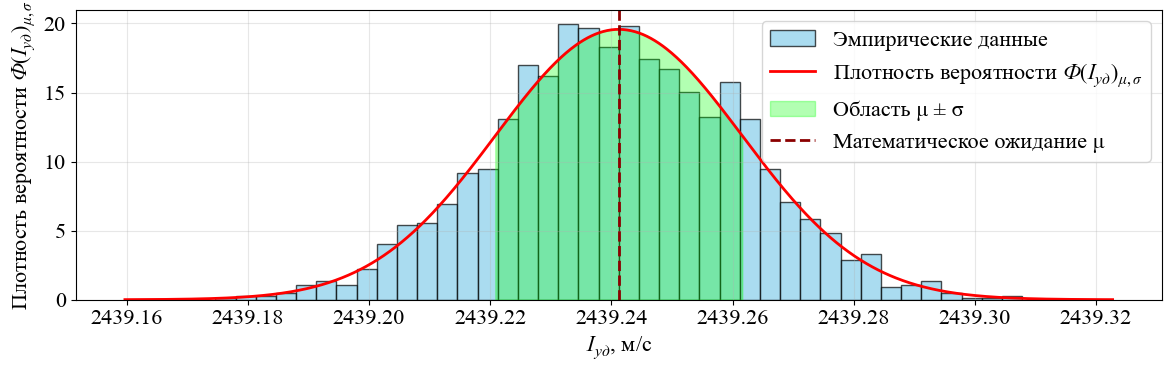

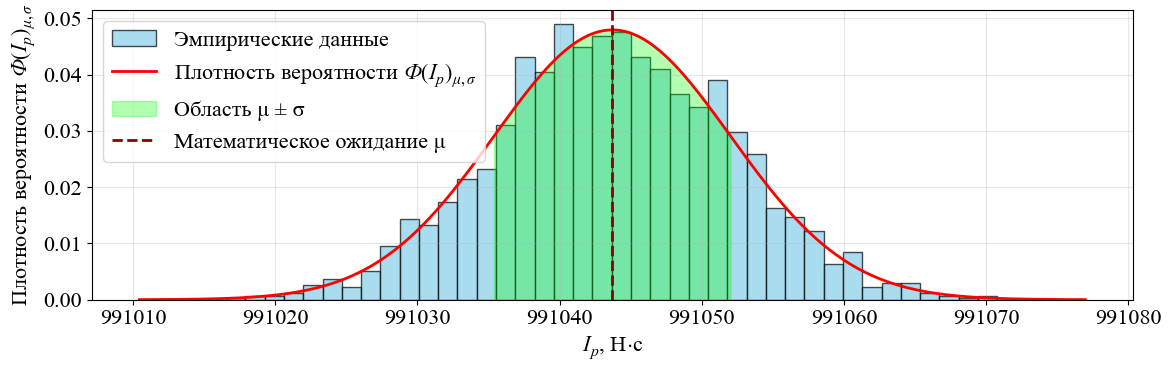

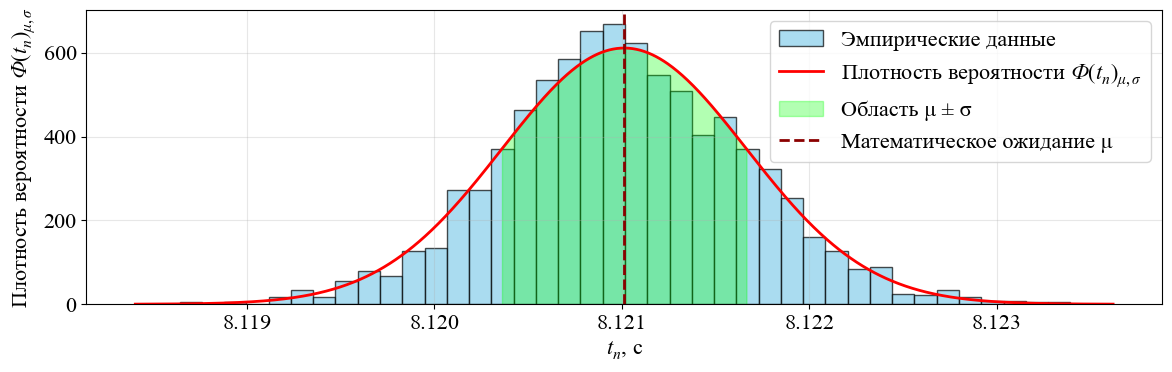

In [71]:
# ============================================================
# 4. УСТОЙЧИВОСТЬ К СЛУЧАЙНОСТИ: bootstrap-разброс среднего
#    (три отдельных графика, оформление как в ноутбуке)
# ============================================================
import matplotlib.pyplot as plt
from scipy import stats

# --- LaTeX-имена для подписей ---
latex_names = {
    'I_p':   r'$I_p$, Н$\cdot$с',
    'I_ud':  r'$I_{уд}$, м/с',
    't_p': r'$t_{п}$, с',
}
latex_names_1 = {
    'I_p':   r'$I_p$',
    'I_ud':  r'$I_{уд}$',
    't_p': r'$t_{п}$',
}

def bootstrap_mean(series, n_boot=2000, seed=42):
    rng = np.random.default_rng(seed)
    x = series.values
    means = np.array([rng.choice(x, size=len(x), replace=True).mean()
                      for _ in range(n_boot)])
    return means

boot_results = {}
for name, col in PARAMS.items():
    means = bootstrap_mean(df[col])
    boot_results[name] = means
    print(f"\n{name}: bootstrap-среднее "
          f"= {means.mean():.6g} ± {means.std():.3g}, "
          f"95% ДИ = [{np.percentile(means, 2.5):.6g}; "
          f"{np.percentile(means, 97.5):.6g}]")

# --- три отдельных графика ---
for name, means in boot_results.items():
    fig, ax = plt.subplots(figsize=(12, 4))

    display_name   = latex_names.get(name, name)
    display_name_1 = latex_names_1.get(name, name)
    clean_name_1   = display_name_1.replace('$', '')

    # Гистограмма
    ax.hist(means, bins=40, density=True, alpha=0.7,
            color='skyblue', edgecolor='black',
            label='Эмпирические данные')

    # Кривая нормального распределения поверх bootstrap
    mu, sigma = np.mean(means), np.std(means, ddof=1)
    x = np.linspace(mu - 4*sigma, mu + 4*sigma, 1000)
    y = stats.norm.pdf(x, mu, sigma)
    ax.plot(x, y, 'r-', linewidth=2,
            label=f'Плотность вероятности $Ф({clean_name_1})_{{\\mu,\\sigma}}$')

    # Область μ ± σ
    x_fill = np.linspace(mu - sigma, mu + sigma, 1000)
    y_fill = stats.norm.pdf(x_fill, mu, sigma)
    ax.fill_between(x_fill, y_fill, alpha=0.3, color='lime',
                    label='Область μ ± σ')

    # Отметка среднего
    ax.axvline(mu, color='darkred', linestyle='--', linewidth=2,
               label='Математическое ожидание μ')

    # Подписи
    ax.set_xlabel(display_name, fontsize=16)
    ax.set_ylabel(f'Плотность вероятности $Ф({clean_name_1})_{{\\mu,\\sigma}}$',
                  fontsize=16)

    ax.legend(loc='best', fontsize=16)
    ax.grid(True, alpha=0.3)
    ax.ticklabel_format(axis='x', style='plain', useOffset=False)
    plt.tight_layout()
    plt.savefig(f'bootstrap_{name}.png', dpi=150)
    plt.show()
    plt.close(fig)

In [72]:
import numpy as np
import pandas as pd

# df уже загружен ранее в ноутбуке
PARAMS = {
    "I_ud":  "I_sp",
    "I_p":   "I_p",
    "t_p": "t_end",
}

print(f"{'Параметр':<8} {'Мат.ожидание':>16} {'Дисперсия':>16} {'СКО':>14} {'Модуль процента разброса':>20}")
print("-" * 85)
for name, col in PARAMS.items():
    x = df[col]
    mean = x.mean()                  # мат. ожидание
    var  = x.var(ddof=1)             # несмещённая дисперсия
    std  = x.std(ddof=1)             # СКО
    delta_min = ((mean-3*std)/mean-1)*100
    delta_max = ((mean+3*std)/mean-1)*100
    delta = abs (delta_min)
    print(f"{name:<8} {mean:>16.6f} {var:>16.6f} {std:>14.6f}  {delta:>20.6f}")

Параметр     Мат.ожидание        Дисперсия            СКО Модуль процента разброса
-------------------------------------------------------------------------------------
I_ud          2439.240736         0.309323       0.556168              0.068403
I_p         991043.512120     51504.539847     226.946117              0.068699
t_p              8.121033         0.000319       0.017872              0.660194
